In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("../data/players_clean.csv")
df["log_value"] = np.log1p(df["market_value_in_eur"])
df.shape

(18404, 17)

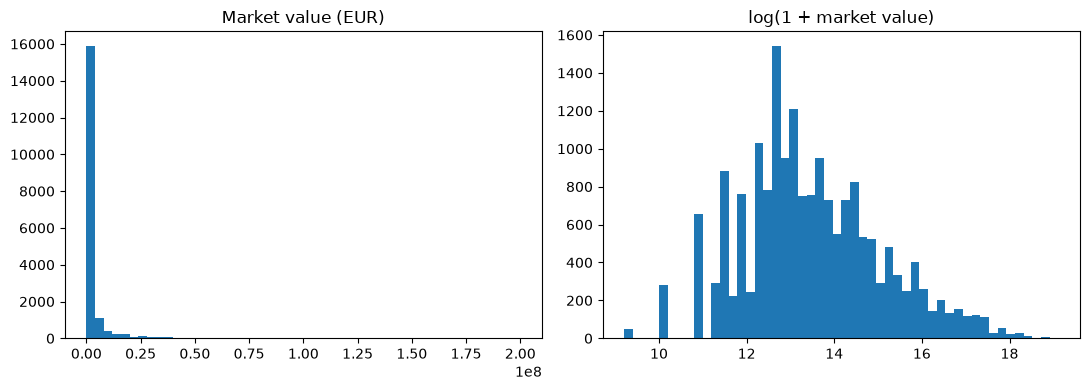

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["market_value_in_eur"], bins=50)
axes[0].set_title("Market value (EUR)")
axes[1].hist(df["log_value"], bins=50)
axes[1].set_title("log(1 + market value)")
plt.tight_layout()
plt.savefig("../images/target_distribution.png", dpi=150)
plt.show()

In [3]:
print(df["market_value_in_eur"].skew())
print(df["log_value"].skew())

8.069171758265917
0.40614815561271034


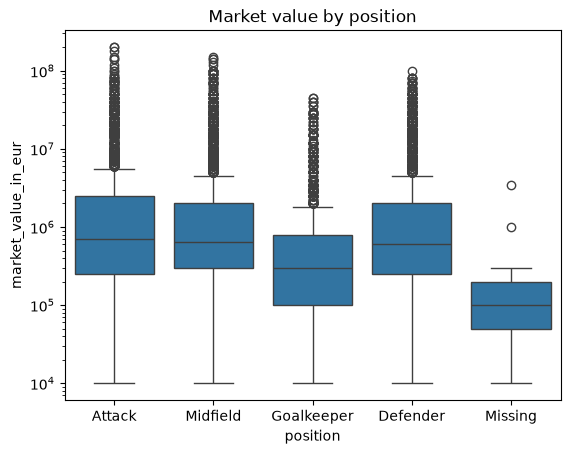

In [4]:
sns.boxplot(data=df, x="position", y="market_value_in_eur")
plt.yscale("log")
plt.title("Market value by position")
plt.savefig("../images/value_by_position.png", dpi=150)
plt.show()

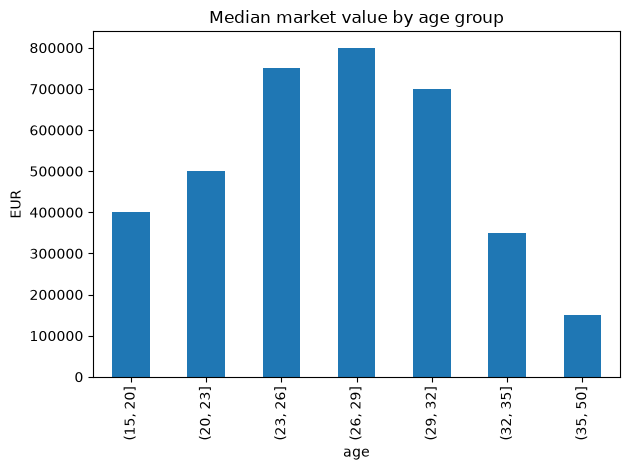

In [5]:
age_bins = pd.cut(df["age"], bins=[15, 20, 23, 26, 29, 32, 35, 50])
df.groupby(age_bins, observed=True)["market_value_in_eur"].median().plot(kind="bar")
plt.title("Median market value by age group")
plt.ylabel("EUR")
plt.tight_layout()
plt.savefig("../images/value_by_age.png", dpi=150)
plt.show()

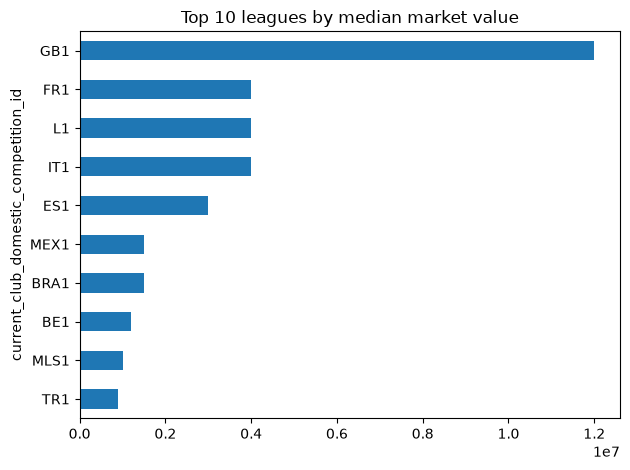

In [6]:
top = df.groupby("current_club_domestic_competition_id")["market_value_in_eur"].median().sort_values(ascending=False).head(10)
top.plot(kind="barh")
plt.title("Top 10 leagues by median market value")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../images/value_by_league.png", dpi=150)
plt.show()

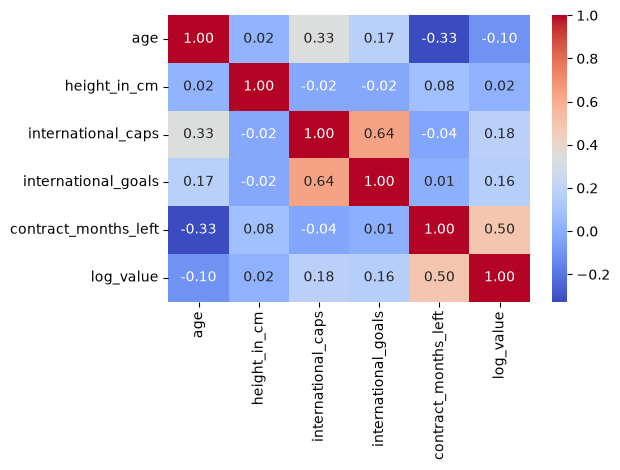

In [7]:
num_cols = ["age", "height_in_cm", "international_caps", "international_goals",
            "contract_months_left", "log_value"]
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.savefig("../images/correlation_heatmap.png", dpi=150)
plt.show()

In [8]:
q1 = df["market_value_in_eur"].quantile(0.25)
q3 = df["market_value_in_eur"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print(upper, (df["market_value_in_eur"] > upper).sum())

4625000.0 2387


In [9]:
groups = [df[df["position"] == p]["log_value"] for p in df["position"].unique()]
stats.f_oneway(*groups)

F_onewayResult(statistic=np.float64(136.35940794312162), pvalue=np.float64(5.0818698722670785e-115))

In [10]:
stats.spearmanr(df["age"], df["log_value"])

SignificanceResult(statistic=np.float64(-0.0470830529697108), pvalue=np.float64(1.6538715953609354e-10))

In [11]:
print(df["position"].value_counts())

position
Defender      6038
Midfield      5262
Attack        5067
Goalkeeper    2008
Missing         29
Name: count, dtype: int64


In [12]:
known = df[df["position"] != "Missing"]
groups = [known[known["position"] == p]["log_value"] for p in known["position"].unique()]
stats.f_oneway(*groups)

F_onewayResult(statistic=np.float64(165.77200642005883), pvalue=np.float64(4.902094056223237e-106))

## EDA findings

1. **The target is heavily right-skewed.** Skewness is 8.07 for market value
   and 0.41 after log(1 + value), so the models predict the log value.
2. **Position matters, mainly for goalkeepers.** A one-way ANOVA gives
   F = 136.4, p = 5.1e-115, so average log value differs across positions.
   Goalkeepers have the lowest median value.
3. **Age has an inverted-U shape.** Median value peaks at about 800,000 EUR for
   ages 26-29 and falls to about 150,000 EUR above 35. The Spearman correlation
   with age is only -0.047 (p = 1.7e-10): significant because of the large
   sample, but small because a rank correlation cannot capture a hump shape.
4. **League is a strong driver.** The Premier League (GB1) has a median of about
   12 million EUR, roughly three times the next leagues (FR1, L1, IT1).
5. **Contract time is the strongest numeric correlate** of log value (0.50),
   though part of this may reflect clubs giving longer contracts to valuable
   players. International caps and goals are correlated with each other (0.64).
6. **Outliers:** 2,387 players (13%) are above the IQR fence of 4.625 million
   EUR. They are real star players, not errors, so they are kept.